# Block 2: Volatility

**Objective.** Measure how the risk of the S&P 500 changes over time, and compare three volatility
estimators: close-to-close, Parkinson (1980) and Garman & Klass (1980).

**Data.** Daily OHLC prices of the S&P 500 (`^GSPC`), 2015-01-02 to 2026-10-30.
All volatilities are annualized with the square-root-of-time rule (252 trading days per year).

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from volrisk.config import FIGURES, TRADING_DAYS
from volrisk.data import load_raw
from volrisk.returns import log_returns
from volrisk.volatility import rolling_volatility, parkinson_volatility, garman_klass_volatility

In [8]:
df = load_raw("sp500")
log_ret = log_returns(df["Close"])
full_sample_vol = log_ret.std() * np.sqrt(TRADING_DAYS)
print(f"Full-sample annualized volatility: {full_sample_vol:.2%}")

Raw data for 'sp500' loaded from 'C:\dev\volatility-analysis\data\raw\sp500.csv'.
Full-sample annualized volatility: 17.65%


## Rolling close-to-close volatility

Volatility is estimated as the standard deviation of daily log returns over a rolling window,
annualized by sqrt(252). This is a historical close-to-close estimator: it uses daily closes only.
Two windows are compared: 21 trading days (one month) reacts quickly to new shocks but is noisy;
63 trading days (one quarter) is smoother but lags behind market turns.

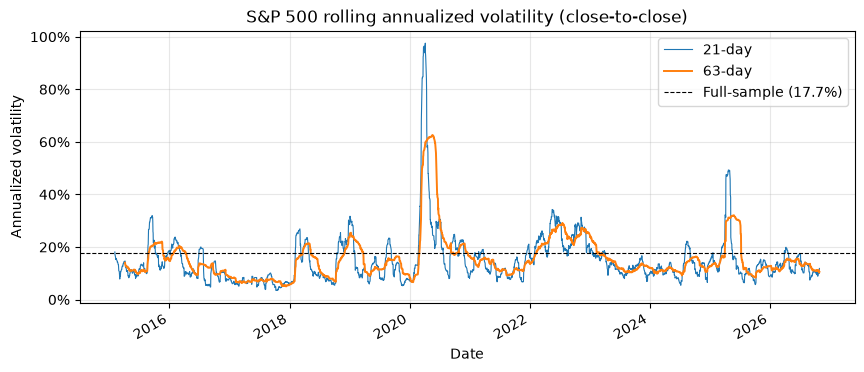

21-day volatility: median 12.4%, max 97.6% on 2020-04-06


In [9]:
vol_21 = rolling_volatility(log_ret, 21)
vol_63 = rolling_volatility(log_ret, 63)

fig, ax = plt.subplots(figsize=(10, 4))
vol_21.plot(ax=ax, linewidth=0.8, label="21-day")
vol_63.plot(ax=ax, linewidth=1.4, label="63-day")
ax.axhline(full_sample_vol, color="black", linestyle="--", linewidth=0.8,
           label=f"Full-sample ({full_sample_vol:.1%})")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("S&P 500 rolling annualized volatility (close-to-close)")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(FIGURES / "02_rolling_volatility.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"21-day volatility: median {vol_21.median():.1%}, max {vol_21.max():.1%} on {vol_21.idxmax().date()}")

C:\Users\admin\AppData\Local\Temp\ipykernel_4348\1987378517.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  vol_cmp = pd.concat([


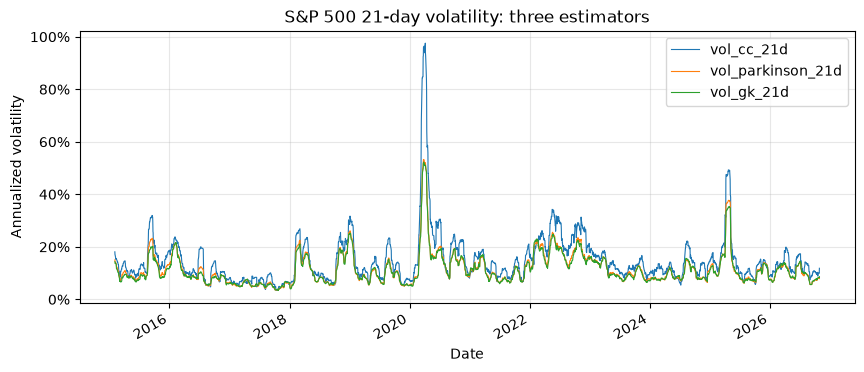

,vol_cc_21d,vol_parkinson_21d,vol_gk_21d
mean,14.80%,11.49%,11.22%
50%,12.37%,9.64%,9.36%
max,97.56%,53.25%,52.29%


In [10]:
vol_cmp = pd.concat([
    rolling_volatility(log_ret, 21),
    parkinson_volatility(df["High"], df["Low"], 21),
    garman_klass_volatility(df["Open"], df["High"], df["Low"], df["Close"], 21),
], axis=1).dropna()

fig, ax = plt.subplots(figsize=(10, 4))
vol_cmp.plot(ax=ax, linewidth=0.8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("S&P 500 21-day volatility: three estimators")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.grid(alpha=0.3)

fig.savefig(FIGURES / "02_volatility_estimators.png", dpi=150, bbox_inches="tight")
plt.show()

vol_cmp.describe().loc[["mean", "50%", "max"]].style.format("{:.2%}")

### Reading the rolling volatility

Volatility is far from constant. Long calm periods, such as 2017 when the 21-day volatility stayed
around 5-8%, alternate with short, violent spikes: August 2015, February and late 2018, March 2020
(about 98% on the 21-day window and 62% on the 63-day window), and April 2025 (about 49%).

Three patterns stand out:
- **Spikes coincide with market sell-offs.** Volatility rises when prices fall, a well-known asymmetry
  called the leverage effect (Black, 1976; Christie, 1982).
- **Volatility rises fast and decays slowly.** After each spike it reverts gradually towards its usual
  level (mean reversion), and the 63-day window lags the 21-day window on the way up and on the way down.
- **Not all stress looks the same.** March 2020 is a sharp, short spike, whereas 2022 shows volatility
  that stays elevated (20-33%) for a whole year, during a prolonged bear market driven by rising interest rates.

Most of the time the 21-day volatility sits below the full-sample average (17.7%): its median is about 12.4%.
The full-sample figure is pulled up by a few crisis episodes.

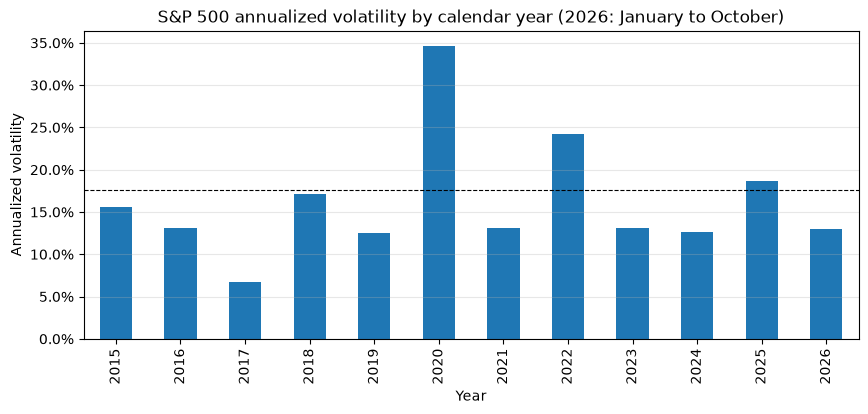

Date
2015    15.54%
2016    13.11%
2017     6.69%
2018    17.10%
2019    12.49%
2020    34.69%
2021    13.11%
2022    24.19%
2023    13.08%
2024    12.67%
2025    18.65%
2026    12.98%
Name: annualized_vol, dtype: str

In [11]:
vol_by_year = (log_ret.groupby(log_ret.index.year).std() * np.sqrt(TRADING_DAYS)).rename("annualized_vol")

fig, ax = plt.subplots(figsize=(10, 4))
vol_by_year.plot.bar(ax=ax)
ax.axhline(full_sample_vol, color="black", linestyle="--", linewidth=0.8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("S&P 500 annualized volatility by calendar year (2026: January to October)")
ax.set_xlabel("Year")
ax.set_ylabel("Annualized volatility")
ax.grid(alpha=0.3, axis="y")

fig.savefig(FIGURES / "02_volatility_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

vol_by_year.map("{:.2%}".format)

In [12]:
regimes = pd.cut(vol_21, bins=[0, 0.10, 0.20, 0.30, np.inf],
                 labels=["Below 10%", "10-20%", "20-30%", "Above 30%"])
regimes.value_counts(normalize=True).sort_index().map("{:.1%}".format)

vol_cc_21d
Below 10%    30.6%
10-20%       51.2%
20-30%       14.2%
Above 30%     4.1%
Name: proportion, dtype: str

## Block 2: key takeaways

- **Volatility is time-varying.** The full-sample annualized volatility of the S&P 500 is 17.7%,
  but the median 21-day volatility is only about 12.4%: markets are calm most of the time and
  experience short, violent spikes, up to about 98% in March 2020.
- **Regimes differ in nature.** Crashes produce sharp, short-lived spikes (March 2020, April 2025),
  whereas 2022 shows volatility that stays elevated for a whole year. By calendar year, volatility ranges
  from about 7% (2017) to about 35% (2020).
- **Volatility rises with falling prices and decays slowly afterwards**, consistent with the leverage
  effect (Black, 1976; Christie, 1982) and with mean reversion in volatility.
- **The choice of estimator matters.** Range-based estimators (Parkinson, 1980; Garman & Klass, 1980)
  give a lower median 21-day volatility (about 9.7% and 9.4%) than the close-to-close estimator (12.4%),
  because they ignore overnight moves between the previous close and the open. For an equity index,
  overnight risk is a significant share of total risk.
- **The window length is a trade-off:** a 21-day window reacts quickly but is noisy; a 63-day window is
  smoother but lags.

These features (fat tails, volatility clustering, asymmetry) are tested formally in **Block 3**,
which studies the distribution of returns.